# Earnings Surprise and Stock Market Reactions

**Jenna Beauchain**

**Industry:** Business Services, SIC 73  
**Client:** Microsoft, MSFT

## Setup and Analysis Dates

Import the packages, connect to WRDS, and define the industry,
date windows, and filtering thresholds.

In [146]:
# Setting up libraries/settings 
# Import Python warning controls.
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)   # hide a harmless pandas warning

# Import pandas as pd for DataFrame operations.
import pandas as pd
# Import the WRDS connection package.
import wrds

conn = wrds.Connection()    # log in to WRDS (type your username and password if asked)

# Settings. If you want to change something, change it here only.
SIC        = "73"             # 2-digit industry 
FY_START   = "2021-01-01"     # First eligible earnings announcement date (rdq). 
FY_END     = "2024-12-31"     # Last eligible announcement date.
PULL_START = "2019-01-01"     # Earlier quarters supply historical EPS and price. (step 4)
PULL_END   = "2024-12-31"     # Last quarterly record date to request.
RET_START  = "2020-12-01"     # Include a trading day before early-2021. (step 7)
RET_END    = "2025-01-31"     # Include a trading day after late-2024. (step 7) 
MIN_PRC = 5  # Require the previous-quarter price to be at least $5.
MAX_CHG = 1  # Require absolute SUE to be no greater than 1. 

Loading library list...
Done


## Step 1 — Prepare the Link File

**Source:** Assignment 8, Step 1, adapted with AI.

Read the instructor's link file and keep companies in SIC 73.
Prepare company identifiers, stock identifiers, and link dates
for matching Compustat and CRSP records.

In [147]:
# Reads columns as text 
link_all = pd.read_csv("ccm_link.csv", dtype=str)

# gvkey must have 6 characters (for example 001690). Excel can drop the leading zeros, so we put them back.
link_all["gvkey"] = link_all["gvkey"].str.zfill(6)

# 1c. permno is a number.
link_all["permno"] = pd.to_numeric(link_all["permno"]).astype(int)

# 1d. The two date columns are text. Turn them into real dates, so that we can compare them with other dates.
# format="mixed" accepts different date formats. errors="coerce" turns a bad value into a missing date.
link_all["linkdt"]    = pd.to_datetime(link_all["linkdt"], format="mixed", errors="coerce")
link_all["linkenddt"] = pd.to_datetime(link_all["linkenddt"], format="mixed", errors="coerce")

# 1e. A link with no end date is still valid, so we give it a far-future end date.
link_all["linkenddt"] = link_all["linkenddt"].fillna(pd.Timestamp("2099-12-31"))

# 1f. Keep only the companies in our industry.
link = link_all[link_all["sic2"] == SIC].reset_index(drop=True)
if len(link) == 0:
    raise ValueError("SIC " + SIC + " is not in ccm_link.csv. Industries in the file: " + str(sorted(link_all["sic2"].unique())))

print("link rows:", len(link), "| companies:", link["gvkey"].nunique())

link rows: 539 | companies: 504


## Step 2 — Pull Quarterly Earnings

**Source:** Assignment 8, adapted with AI.

Pull quarterly EPS, prices, fiscal periods, and announcement dates.
Earlier quarters provide the historical EPS and price inputs
needed to calculate SUE.

In [148]:
# 2a. The SQL query needs the gvkeys as one text:  '001690','002176',...
gv = "'" + "','".join(link["gvkey"].unique()) + "'"

# 2b. Ask WRDS for only the rows and columns we need.
q = conn.raw_sql(f"""
    select gvkey, datadate, fyearq, fqtr, rdq, epspxq, prccq
    from comp.fundq
    where gvkey in ({gv})
      and datadate between '{PULL_START}' and '{PULL_END}'
      and indfmt = 'INDL' and datafmt = 'STD' and popsrc = 'D' and consol = 'C'
""", date_cols=["datadate", "rdq"])

# 2c. WRDS can return numbers in a special type. Turn them into plain decimal numbers (a missing value becomes NaN).
q["epspxq"]  = q["epspxq"].astype("float64")
q["prccq"] = q["prccq"].astype("float64")

# 2d. Check what we got.
print("company-years pulled from Compustat:", len(q))

company-years pulled from Compustat: 9866


## Step 3 — Merge 1: Attach Stock Identifiers

**Source:** Assignment 8, Steps 3a–3b, adapted with AI.

Match quarterly records to stock identifiers using gvkey.
Keep links valid on the quarter-end date, check repeated keys,
and print the row counts.

In [149]:
# add permno from link file 

print("Before Merge 1:", len(q))

panel = q.merge(
    link[["gvkey", "permno", "ticker", "linkdt", "linkenddt"]], 
    on="gvkey", how="inner")

print("After matching gvkey", len(panel))

Before Merge 1: 9866
After matching gvkey 10570


In [150]:
# Keep only the link that was valid on the fiscal end-year date 

# Check whether each link was valid on the quarter-end date
valid = (panel["linkdt"] <= panel["datadate"]) & (panel["datadate"] <= panel["linkenddt"])

# Keep only valid links 
panel = panel[valid]

# Count rows after applying the link dates 
print("After keeping valid links:", len(panel))

# Count repeated company-quarter keys
n_dup = panel.duplicated(["gvkey", "datadate"]).sum()

# Count repeated company-quarter keys 
print("3b. rows that repeat a gvkey + datadate before we drop them:", n_dup)

# If one company-year still has two rows, keep one.
panel = panel.drop_duplicates(["gvkey", "datadate"])

# We do not need the link dates any more.
panel = panel.drop(columns=["linkdt", "linkenddt"]).reset_index(drop=True)

# Count (used in the sample construction table in Step 6).
r1, c1 = len(q), q["gvkey"].nunique()          # before the link
r2, c2 = len(panel), panel["gvkey"].nunique()    # after the link
print("3b. company-years after the link merge:", r2)

After keeping valid links: 8919
3b. rows that repeat a gvkey + datadate before we drop them: 8
3b. company-years after the link merge: 8911


In [151]:
# ===== Check: does any key (gvkey + fyear) appear more than once? =====
# duplicated() marks a row True if an earlier row has the same gvkey and fyear. sum() counts the True values.
print("duplicate keys:", panel.duplicated(["gvkey", "datadate"]).sum(), "(it must be 0)")

duplicate keys: 0 (it must be 0)


In [152]:
# Final counts after Merge 1

# Save the final counts after Merge 1.
r2 = len(panel)
c2 = panel["gvkey"].nunique()

# Display the final row count.
print("Company-quarters after Merge 1:", r2)

Company-quarters after Merge 1: 8911


## Step 4 — Merge 2: Attach EPS from Four Quarters Earlier

**Source:** Inclass_quarter_numbers_and_day0, adapted with AI.

Calculate the fiscal-quarter number and check that each company
and fiscal quarter identifies one record.

Shift the quarter number in the historical EPS copy forward by four.
Match on gvkey and qnum to attach EPS from four quarters earlier.

In [153]:
# Add earlier EPS

# Calculate the quarter number, following the in-class example.
panel["qnum"] = panel["fyearq"] * 4 + panel["fqtr"]

# Check whether each company and fiscal quarter identifies one row.
print("Duplicate fiscal-quarter keys:", panel.duplicated(["gvkey", "qnum"]).sum())


Duplicate fiscal-quarter keys: 7


In [154]:
# Removes duplicate records (additional code)

# Count rows before removing repeated fiscal-quarter keys.
print("Before fiscal-quarter duplicate removal:", len(panel))

# Keep the first record for each company and fiscal-quarter number.
panel = panel.drop_duplicates(["gvkey", "qnum"])

# Reset row numbers, following the professor's code.
panel = panel.reset_index(drop=True)

# Count rows after removing repeated keys.
print("After fiscal-quarter duplicate removal:", len(panel))

# Confirm the matching key is now unique.
print("Duplicate fiscal-quarter keys:", panel.duplicated(["gvkey", "qnum"]).sum())

Before fiscal-quarter duplicate removal: 8911
After fiscal-quarter duplicate removal: 8904
Duplicate fiscal-quarter keys: 0


In [155]:
# Make the earlier EPS table

# Copy the company ID, quarter number, and EPS.
eps4 = panel[["gvkey", "qnum", "epspxq"]].copy()

# Move the quarter number forward by four.
eps4["qnum"] = eps4["qnum"] + 4

# Rename EPS so it is distinct from current-quarter EPS.
eps4 = eps4.rename(columns={"epspxq": "eps_4q_ago"})

In [156]:
# Merge back together 

# Print the number of rows before Merge 2.
print("Before Merge 2:", len(panel))

# Attach EPS from four quarters earlier, keeping every current row.
panel = panel.merge(eps4, on=["gvkey", "qnum"], how="left")

# Print the number of rows after Merge 2.
print("After Merge 2:", len(panel))

Before Merge 2: 8904
After Merge 2: 8904


## Step 5 — Merge 3: Attach Last Quarter's Price

**Source:** Inclass_quarter_numbers_and_day0, adapted with AI.

Copy quarterly prices and shift their quarter numbers forward by one.
Match on gvkey and qnum to attach the previous-quarter price.
Keep unmatched observations for the later filtering rules.

In [157]:
# Prepare previous quarter prices

# Copy the company ID, quarter number, and price.
prc1 = panel[["gvkey", "qnum", "prccq"]].copy()

# Move each quarter number forward by one.
prc1["qnum"] = prc1["qnum"] + 1

# Give the earlier price a separate name.
prc1 = prc1.rename(columns={"prccq": "prc_1q_ago"})

In [158]:
# Merge back together 

# Count rows before the price merge.
print("Before Merge 3:", len(panel))

# Attach the previous-quarter price using company and quarter number.
panel = panel.merge(prc1, on=["gvkey", "qnum"], how="left")

# Count rows after the price merge.
print("After Merege 3:", len(panel))

Before Merge 3: 8904
After Merege 3: 8904


## Step 6 — Calculate SUE

**Source:** Inclass_quarter_numbers_and_day0, adapted with AI.

Calculate SUE as current EPS minus EPS four quarters earlier,
divided by the previous-quarter price.

In [159]:
# Calculate SUE using the three earnings-surprise inputs.
panel["sue"] = (panel["epspxq"] - panel["eps_4q_ago"]) / panel["prc_1q_ago"]

# Select the inputs and calculated SUE.
show = ["gvkey", "fyearq", "fqtr", "epspxq", "eps_4q_ago", "prc_1q_ago", "sue"]

In [160]:
# Count rows with a calculated SUE 

# Count rows with a calculated SUE.
print("Rows with SUE:", panel["sue"].notna().sum())


Rows with SUE: 6879


## Step 7 — Define Rules 1–5

**Source:** Week 10 filtering example, adapted with AI.

Require a known announcement date, an announcement during 2021–2024,
available SUE inputs, a nonzero denominator, a previous-quarter price
of at least $5, and absolute SUE no greater than 1.

In [161]:
# Rule 1: the announcement date is known.
rule1 = panel["rdq"].notna()  

# Rule 2: the announcement date is January 2021-December 2024
rule2 = panel["rdq"].between(FY_START, FY_END)  

# Rule 3: current EPS is present
rule3 = panel["epspxq"].notna()  

# Require EPS from four quarters ago
rule3 = rule3 & panel["eps_4q_ago"].notna()

# Require last quarter's price
rule3 = rule3 & panel["prc_1q_ago"].notna()

# Require a nonzero demoninator so SUE can be computed
rule3 = rule3 & (panel["prc_1q_ago"] != 0)

# Rule 4: last quarter's price is at least $5.
rule4 = panel["prc_1q_ago"] >= MIN_PRC
              
# Rule 5: absolute SUE is at most 1
rule5 = panel["sue"].abs() <= MAX_CHG


### Apply Rules 1–5

Apply each rule separately and print the number of rows before
and after it. Save the remaining announcements as events.

In [162]:
# Show the starting count.
print("Before rules:", len(panel))

# Apply Rule 1.
d1 = panel[rule1]
print("Rule 1:", len(panel), "before;", len(d1), "after")
print("Reason Removed: Missing announcement date.")
print()

# Apply Rule 2.
d2 = d1[rule2[d1.index]]
print("Rule 2:", len(d1), "before;", len(d2), "after")
print("Reason Removed: Announcement outside the required period.")
print()

# Apply Rule 3.
d3 = d2[rule3[d2.index]]
print("Rule 3:", len(d2), "before;", len(d3), "after")
print("Reason Removed: Missing input or zero previous-quarter price.")
print()

# Apply Rule 4.
d4 = d3[rule4[d3.index]]
print("Rule 4:", len(d3), "before;", len(d4), "after")
print("Reason Removed: Previous-quarter price below $5.")
print()

# Apply Rule 5.
d5 = d4[rule5[d4.index]]
print("Rule 5:", len(d4), "before;", len(d5), "after")
print("Reason Removed: Absolute SUE above 1.")

# Save the remaining announcements for the daily-return step.
events = d5.copy()

Before rules: 8904
Rule 1: 8904 before; 8706 after
Reason Removed: Missing announcement date.

Rule 2: 8706 before; 5932 after
Reason Removed: Announcement outside the required period.

Rule 3: 5932 before; 5526 after
Reason Removed: Missing input or zero previous-quarter price.

Rule 4: 5526 before; 4200 after
Reason Removed: Previous-quarter price below $5.

Rule 5: 4200 before; 4195 after
Reason Removed: Absolute SUE above 1.


## Step 8 — Pull Daily Returns and Calculate CAR

**Source:** Assignment 8 and the in-class trading-day and CAR examples,
adapted with AI.

Pull daily stock returns for the retained stocks and daily market
returns from December 2020 through January 2025.

In [163]:
# Get the stock IDs for the announcements that passed the rules.
permnos = ",".join(events["permno"].astype(str).unique())

# Pull daily stock returns.
dsf = conn.raw_sql(f"""
    select permno, date, ret
    from crsp.dsf
    where permno in ({permnos})
      and date between '{RET_START}' and '{RET_END}'
""", date_cols=["date"])

# Pull daily market returns.
dsi = conn.raw_sql(f"""
    select date, vwretd
    from crsp.dsi
    where date between '{RET_START}' and '{RET_END}'
""", date_cols=["date"])

# Convert stock IDs to integers.
dsf["permno"] = dsf["permno"].astype(int)

# Convert stock returns to decimal numbers.
dsf["ret"] = dsf["ret"].astype("float64")

# Convert market returns to decimal numbers.
dsi["vwretd"] = dsi["vwretd"].astype("float64")

# Reset announcement row numbers for event IDs.
events = events.reset_index(drop=True)

# Show the number of daily records pulled.
print("Daily stock rows:", len(dsf))
print("Daily market rows:", len(dsi))

Daily stock rows: 340398
Daily market rows: 1027


### 8.1 — Number Market Trading Days

Sort the market calendar and assign consecutive trading-day numbers.
These numbers allow event windows to skip weekends and market holidays.

In [164]:
# Trading day number

# Put market trading dates in chronological order.
dsi = dsi.sort_values("date").reset_index(drop=True)

# Number trading days 1, 2, 3, ...
dsi["tday"] = dsi.index + 1

### 8.2 — Merge 4: Attach Market Returns

Match stock and market returns by date.
Calculate abnormal return as stock return minus market return.

In [165]:
# Merge 4: market return and trading-day number

# Count stock-day rows before the merge.
print("Before Merge 4:", len(dsf))

# Add the market return and trading-day number for the same date.
daily = dsf.merge(dsi[["date", "vwretd", "tday"]], on="date", how="left")

# Count stock-day rows after the merge.
print("After Merge 4:", len(daily))

# Calculate daily abnormal returns.
daily["ar"] = daily["ret"] - daily["vwretd"]

Before Merge 4: 340398
After Merge 4: 340398


### 8.3 — Identify Day 0

Select the first market trading day on or after each announcement date.

In [166]:
# Day 0 

# Give each announcement its own identifier.
events["event_id"] = events.index

# Count announcements before pairing with market days.
print("Before announcement-calendar cross merge:", len(events))

# Pair every announcement with every market trading day.
pairs = events[["event_id", "rdq"]].merge(dsi[["date", "tday"]], how="cross")

# Count the announcement-calendar pairs.
print("After announcement-calendar cross merge:", len(pairs))

# Keep trading dates on or after the announcement.
pairs = pairs[pairs["date"] >= pairs["rdq"]]

# Find the first eligible trading-day number for each announcement.
day0 = pairs.groupby("event_id")["tday"].min().reset_index()

# Name that trading-day number day0.
day0 = day0.rename(columns={"tday": "day0"})

# Count announcements before attaching day 0.
print("Before day0 merge:", len(events))

# Attach day 0 to each announcement.
events = events.merge(day0, on="event_id", how="left")

# Count announcements after attaching day 0.
print("After day0 merge:", len(events))


Before announcement-calendar cross merge: 4195
After announcement-calendar cross merge: 4308265
Before day0 merge: 4195
After day0 merge: 4195


### 8.4 — Build Three-Day Event Windows

Create three rows per announcement for trading-day offsets −1, 0, and +1.

In [167]:
# Three days per announcement 

# Create the three event-day positions.
offsets = pd.DataFrame({"offset": [-1, 0, 1]})

# Count announcements before creating the three-day window.
print("Before window cross merge:", len(events))

# Create three rows per announcement.
window = events[["event_id", "permno", "day0"]].merge(offsets, how="cross")

# Count the announcement-day rows.
print("After window cross merge:", len(window))

# Calculate the trading-day number for each required day.
window["tday"] = window["day0"] + window["offset"]


Before window cross merge: 4195
After window cross merge: 12585


### 8.5 — Merge 5: Attach Daily Abnormal Returns

Match each required event day using permno and tday.
Keep unmatched days visible as missing returns.

In [168]:
# Merge 5: attach each day's abnormal return

# Count required announcement-day rows before the merge.
print("Before Merge 5:", len(window))

# Match the stock and trading-day number to its abnormal return.
window = window.merge(
    daily[["permno", "tday", "ar"]],
    on=["permno", "tday"],
    how="left"
)

# Count announcement-day rows after the merge.
print("After Merge 5:", len(window))


Before Merge 5: 12585
After Merge 5: 12585


### 8.6 — Calculate CAR

Sum the abnormal returns for each announcement.
Count how many nonmissing daily abnormal returns were found.

In [169]:
# CAR

# Sum abnormal returns and count nonmissing returns per announcement.
car = window.groupby("event_id")["ar"].agg(["sum", "count"]).reset_index()

# Give the results clear column names.
car = car.rename(columns={"sum": "car", "count": "days_found"})

# Count announcements before attaching CAR.
print("Before CAR merge:", len(events))

# Attach CAR and the number of available returns.
events = events.merge(car, on="event_id", how="left")

# Count announcements after attaching CAR.
print("After CAR merge:", len(events))

Before CAR merge: 4195
After CAR merge: 4195


### 8.7 — Apply Rule 6

Keep announcements with all three required daily abnormal returns.
Save the retained announcements in the final analysis table.

In [170]:
# Rule 6: all three daily abnormal returns exist 

# Count announcements before Rule 6.
print("Before Rule 6:", len(events))

# Keep only announcements with all three abnormal returns.
final = events[events["days_found"] == 3]

# Count announcements after Rule 6.
print("After Rule 6:", len(final))

Before Rule 6: 4195
After Rule 6: 4185


## Step 9 — Validate the Final Sample

### Check 2 — Unique Company-Quarter Keys

Check that each gvkey and datadate combination appears only once.
Check 1 row counts are printed throughout the earlier merges and rules.

In [171]:
# Check 2. Verify that each final company-quarter appears once.
# Source: Professor's duplicate-check method, adapted with ChatGPT.

# Count repeated company and quarter-end combinations.
n_dup = final.duplicated(["gvkey", "datadate"]).sum()

# Display the count; it should be zero.
print("Duplicate company-quarter keys:", n_dup, "(must be 0)")

Duplicate company-quarter keys: 0 (must be 0)


### Check 3 — Announcement and Trading Dates

Check that announcement dates follow quarter-end dates.
Verify that day 0 corresponds to an actual market trading date.

In [172]:
# Check 3. Verify announcement dates and day-0 trading dates.
# Source: AI-assisted checks using the professor's trading-day calendar.

# Part A: mark announcements on or before the quarter-end date.
bad_dates = final["rdq"] <= final["datadate"]

# Count these observations; the expected result is zero.
print("Announcements on or before quarter end:", bad_dates.sum())

# Count missing dates separately because missing values cannot pass a check.
missing_dates = final["rdq"].isna() | final["datadate"].isna()
print("Rows with missing announcement or quarter-end dates:", missing_dates.sum())

# Part B: copy the market's trading-day numbers and actual dates.
calendar = dsi[["tday", "date"]].copy()

# Rename columns to match day0 without overwriting the announcement date.
calendar = calendar.rename(columns={
    "tday": "day0",
    "date": "day0_date"
})

# Count rows before attaching calendar dates.
print("Before date-check merge:", len(final))

# Look up the actual trading date for each announcement's day0 number.
date_check = final.merge(calendar, on="day0", how="left")

# Count rows afterward; the count should stay the same.
print("After date-check merge:", len(date_check))

# Verify that each looked-up date exists in the daily market calendar.
is_trading_day = date_check["day0_date"].isin(dsi["date"])

# Count missing or invalid day-0 dates; the expected result is zero.
print("Day 0 missing or not a market trading day:", (~is_trading_day).sum())

# Check that day 0 never falls before the announcement.
before_announcement = date_check["day0_date"] < date_check["rdq"]
print("Day 0 before announcement:", before_announcement.sum())

Announcements on or before quarter end: 0
Rows with missing announcement or quarter-end dates: 0
Before date-check merge: 4185
After date-check merge: 4185
Day 0 missing or not a market trading day: 0
Day 0 before announcement: 0


### Check 4 — Five Largest Absolute CARs

Identify the five largest CAR magnitudes while keeping their signs.
Investigate these observations rather than assuming large values are errors.

In [173]:
# Check 4. Identify the five largest absolute CARs.
# Source: Week 10 extremes example, adapted with ChatGPT for CAR.

# Select a few columns so the output fits on the page.
cols = ["ticker", "datadate", "rdq", "sue", "car"]

# Find the row labels of the five largest CAR magnitudes.
extreme_index = final["car"].abs().nlargest(5).index

# Keep the original signed CAR values for these announcements.
extremes = final.loc[extreme_index, cols].copy()


In [174]:
# Check 4 continued. - creates extreme-day: the three event-day
# rows for each of the 5 announcement dates 

#### Inspect the Extreme Event Windows

Select the three event-day records for each of the five extreme announcements.

In [175]:
# Inspect the daily inputs behind the five extreme CARs.
# Source: AI-assisted diagnostic using the professor's event-window tables.

# Get the event IDs of the five extreme announcements.
extreme_ids = final.loc[extreme_index, "event_id"]

# Keep their three-day window records.
extreme_days = window[window["event_id"].isin(extreme_ids)].copy()

# Sort by announcement and event-day position.
extreme_days = extreme_days.sort_values(["event_id", "offset"])

In [176]:
# Check 4. continued - uses extreme_days and adds the actual 
# date, stock returns, and market returns to study and conclude
# if the CAR values are a data error or a real event

#### Inspect Dates and Return Components

Attach the actual dates, stock returns, and market returns.
Use these inputs to investigate the large CAR values.

In [177]:
# Select the stock identifiers and trading dates needed for verification.
daily_inputs = daily[["permno", "tday", "date", "ret", "vwretd"]].copy()

# Count event-day rows before adding the inputs.
print("Before input-check merge:", len(extreme_days))

# Attach the date, stock return, and market return for each event day.
extreme_detail = extreme_days.merge(
    daily_inputs,
    on=["permno", "tday"],
    how="left"
)

# Confirm the merge did not multiply event-day rows.
print("After input-check merge:", len(extreme_detail))

# Select only the columns needed for inspection.
check_cols = ["event_id", "offset", "date", "ret", "vwretd", "ar"]


Before input-check merge: 15
After input-check merge: 15


### Check 5 — Verify One Client Announcement

Select one Microsoft announcement.
Compare its EPS and previous-quarter price with independent sources.

In [178]:
# Check 5. Select one client announcement for input verification.
# Source: Professor's single-row inspection approach, adapted with ChatGPT.

# Keep Microsoft announcements from the final analysis table.
client = final[final["ticker"] == "MSFT"].copy()

# Sort announcements by date.
client = client.sort_values("rdq")

# Count available client announcements.
print("Microsoft announcements available:", len(client))

# Choose columns needed to verify the inputs.
input_cols = [
    "ticker", "datadate", "rdq",
    "epspxq", "eps_4q_ago", "prc_1q_ago"
]


Microsoft announcements available: 16


### Check 6 — Rebuild One Announcement by Hand

Display the same announcement and its daily return inputs.
Independently calculate SUE and CAR in Excel or with a calculator,
then compare them with the notebook values.

In [179]:
# Check 6. Display inputs for a hand calculation of the Check 5 announcement.
# Source: AI-assisted inspection using the professor's event-window tables.

# Select the same earliest Microsoft announcement used in Check 5.
chosen = client.head(1).copy()

# Display its inputs and the notebook's calculated SUE and CAR.
cols = [
    "ticker", "datadate", "rdq",
    "epspxq", "eps_4q_ago", "prc_1q_ago", "sue", "car"
]

# Get the unique event ID for this announcement.
chosen_id = chosen["event_id"].iloc[0]

# Keep its three event days: -1, 0, and +1.
chosen_days = window[window["event_id"] == chosen_id].copy()

# Attach actual trading dates, stock returns, and market returns.
inputs = daily[["permno", "tday", "date", "ret", "vwretd"]].copy()
chosen_days = chosen_days.merge(
    inputs,
    on=["permno", "tday"],
    how="left",
    validate="many_to_one"
)

# Display the days in order, with enough precision for the hand calculation.
chosen_days = chosen_days.sort_values("offset")
cols = ["offset", "date", "ret", "vwretd", "ar"]

In [180]:
# select one announcement of one company and make sure all calculations are correct 
# panel[panel["gvkey"] == "001076"]

## Step 10 — Compare Average CAR across SUE Groups

**Source:** Week 10 ranking method, adapted with AI.

Rank announcements by SUE and divide them into three approximately
equal groups: Low, Middle, and High.

Count announcements and calculate average CAR in each group.

In [181]:
# Step 10. Compare average CAR across three SUE groups.
# Source: Week 10 ranking method; summary code adapted with ChatGPT.

# Copy the final analysis table so we can add a group column.
results = final.copy()

# Rank SUE from lowest to highest.
# method="first" breaks ties using the existing row order.
sue_rank = results["sue"].rank(method="first")

# Split the ranked announcements into three groups of nearly equal size.
results["sue_group"] = pd.qcut(
    sue_rank,
    3,
    labels=["Low", "Middle", "High"]
)

# Count announcements and calculate average CAR within each group.
summary = results.groupby("sue_group", observed=True)["car"].agg(["count", "mean"])

# Give the summary columns clear labels.
summary = summary.rename(columns={
    "count": "Number of announcements",
    "mean": "Average CAR"
})
# Display the aggregate results table.
display(summary)

,Number of announcements,Average CAR
sue_group,,
Low,1395,-0.016247
Middle,1395,-0.002555
High,1395,0.016364


### 10.1 — Attach Group Labels to the Final Table

Add the SUE group labels to final for the following checks.
The main summary table uses a separate copy named results.

In [182]:
# Add SUE group labels to the individual announcements.
# Source: Professor's ranking method, adapted with AI.
final = final.copy()
final["sue_group"] = pd.qcut(
    final["sue"].rank(method="first"),
    3,
    labels=["Low", "Middle", "High"]
)

# Confirm that the labels now exist.
print(final["sue_group"].value_counts(sort=False))

sue_group
Low       1395
Middle    1395
High      1395
Name: count, dtype: int64


### 10.2 — Q1: Company Representation

Count different companies in each SUE group.
Identify the company contributing the most announcements to each group.

In [183]:
# Part 4, Q1. Check how many companies contribute to each SUE group.
# Source: AI-assisted checks using pandas grouping and counting.

# Count distinct companies in each group.
company_counts = final.groupby(
    "sue_group", observed=True
)["gvkey"].nunique()

print("Different companies in each SUE group:")
print(company_counts)

# Count announcements from each company within each group.
company_frequency = final.groupby(
    ["sue_group", "gvkey"], observed=True
).size().reset_index(name="announcements")

# Put the largest company counts first within each group.
company_frequency = company_frequency.sort_values(
    ["sue_group", "announcements"],
    ascending=[True, False]
)

# Show the company contributing the most announcements to each group.
largest_company = company_frequency.groupby(
    "sue_group", observed=True
).head(1)
# Display group counts without identifying individual companies.
display(largest_company[["sue_group", "announcements"]])


Different companies in each SUE group:
sue_group
Low       326
Middle    272
High      330
Name: gvkey, dtype: int64


,sue_group,announcements
205,Low,12
329,Middle,16
885,High,13


### 10.3 — Q1: Company and Quarter Influence

Temporarily omit each company and each announcement calendar quarter.
Measure how much each omission changes the group's average CAR.

In [184]:
# Part 4, Q1. Check sensitivity to individual companies and quarters.
# Source: AI-assisted diagnostic.

# Work with a separate copy of the final results.
sample_check = final.copy()

# Identify the calendar quarter of each announcement.
sample_check["announcement_quarter"] = (
    sample_check["rdq"].dt.to_period("Q")
)

# Examine each SUE group separately.
for group in ["Low", "Middle", "High"]:
    group_rows = sample_check[sample_check["sue_group"] == group]
    original_mean = group_rows["car"].mean()

    print("\nSUE group:", group)
    print("Original average CAR:", round(original_mean, 6))

    # Omit each company, then each announcement quarter.
    for key in ["gvkey", "announcement_quarter"]:
        biggest_change = 0
        biggest_id = None
        changed_mean = original_mean

        for value in group_rows[key].unique():
            remaining = group_rows[group_rows[key] != value]
            new_mean = remaining["car"].mean()
            change = abs(new_mean - original_mean)

            if change > biggest_change:
                biggest_change = change
                biggest_id = value
                changed_mean = new_mean

# Report only the aggregate sensitivity result.
print("Exclusion type:", key)
print("Absolute change in group average:", round(biggest_change, 6))


SUE group: Low
Original average CAR: -0.016247

SUE group: Middle
Original average CAR: -0.002555

SUE group: High
Original average CAR: 0.016364
Exclusion type: announcement_quarter
Absolute change in group average: 0.00217


### 10.4 — Q2: Remove the Five Extreme CARs

Display the original group table.
Create a separate sample excluding the five extremes identified in Check 4.

In [185]:
# Part 4, Q2. Rebuild the results without the five Check 4 extremes.
# Source: Professor's ranking method, adapted with AI.

# Show the original group counts and average CARs.
before = final.groupby(
    "sue_group", observed=True
)["car"].agg(["count", "mean"])

print("BEFORE removing the five extremes:")
display(before)

# Identify the same five largest absolute CARs used in Check 4.
extreme_index = final["car"].abs().nlargest(5).index

# Remove those five announcements from a separate copy.
trimmed = final.drop(index=extreme_index).copy()


BEFORE removing the five extremes:


,count,mean
sue_group,,
Low,1395,-0.016247
Middle,1395,-0.002555
High,1395,0.016364


### 10.5 — Q2: Rebuild and Compare the Groups

Rank the remaining announcements by SUE and recreate the three groups.
Compare the ordering of average CARs before and after removing the extremes.

In [186]:
# Rank the remaining announcements by SUE.
sue_rank = trimmed["sue"].rank(method="first")

# Recreate three approximately equal groups.
trimmed["sue_group"] = pd.qcut(
    sue_rank,
    3,
    labels=["Low", "Middle", "High"]
)

# Calculate the counts and average CARs after removing the extremes.
after = trimmed.groupby(
    "sue_group", observed=True
)["car"].agg(["count", "mean"])

print("AFTER removing the five extremes:")
print("Remaining announcements:", len(trimmed))
display(after)

# Compare the order from lowest to highest average CAR.
print("Order before:", before["mean"].sort_values().index.tolist())
print("Order after:", after["mean"].sort_values().index.tolist())

AFTER removing the five extremes:
Remaining announcements: 4180


,count,mean
sue_group,,
Low,1393,-0.015251
Middle,1393,-0.002589
High,1394,0.014517


Order before: ['Low', 'Middle', 'High']
Order after: ['Low', 'Middle', 'High']


### 10.6 — Q3: Microsoft's Largest Reaction

Select Microsoft's largest absolute CAR from the original final sample.
Read the associated earnings release and news, compare the signs of SUE
and CAR, and explain the evidence in your own words.

In [187]:
# Part 4, Q3. Find Microsoft's largest absolute announcement CAR.
# Source: Professor's extremes method, adapted with AI.

# Keep Microsoft announcements from the original final sample.
msft = final[final["ticker"] == "MSFT"].copy()

# Find the announcement with the largest CAR magnitude.
biggest_index = msft["car"].abs().nlargest(1).index


## Step 11 — Preserve the Business Services Sample

Save a copy of the final Business Services sample before preparing
the comparison industry, Eating & Drinking Places (SIC 58).

**Source:** AI-assisted organization.

In [188]:
# Preserve the completed Business Services sample.
business_final = final.copy()

# Confirm the number of saved announcements.
print("Business Services announcements saved:", len(business_final))

Business Services announcements saved: 4185


## Step 12 — Prepare the Comparison Industry

Select Eating & Drinking Places (SIC 58).
Use the same dates, merges, and filtering rules as Business Services.

**Source:** Existing Project 2 code, adapted with AI.

In [189]:
# Select comparison-industry links from the original link table.
comparison_link = link_all[link_all["sic2"] == "58"].copy()

# Reset row numbers.
comparison_link = comparison_link.reset_index(drop=True)

# Check the number of links and distinct companies.
print("Comparison-industry links:", len(comparison_link))
print("Comparison-industry companies:", comparison_link["gvkey"].nunique())

Comparison-industry links: 42
Comparison-industry companies: 36


## Step 13 — Pull Comparison-Industry Quarterly Earnings

Pull quarterly EPS, prices, fiscal periods, and announcement dates
for Eating & Drinking Places (SIC 58), using the same dates and
Compustat filters as Business Services.

**Source:** Existing Project 2 quarterly-pull code, adapted with AI.

In [190]:
# Format the comparison-company identifiers for the SQL query.
comparison_gv = "'" + "','".join(comparison_link["gvkey"].unique()) + "'"

# Pull the same quarterly variables using the original dates and filters.
comparison_q = conn.raw_sql(f"""
    select gvkey, datadate, fyearq, fqtr, rdq, epspxq, prccq
    from comp.fundq
    where gvkey in ({comparison_gv})
      and datadate between '{PULL_START}' and '{PULL_END}'
      and indfmt = 'INDL'
      and datafmt = 'STD'
      and popsrc = 'D'
      and consol = 'C'
""", date_cols=["datadate", "rdq"])

# Convert EPS to a standard numeric type.
comparison_q["epspxq"] = comparison_q["epspxq"].astype("float64")

# Convert quarterly stock prices to a standard numeric type.
comparison_q["prccq"] = comparison_q["prccq"].astype("float64")

# Report the number of quarterly records pulled.
print("Comparison quarterly records:", len(comparison_q))


Comparison quarterly records: 810


## Step 14 — Match Comparison-Industry Quarterly Records

Apply the same link-date checks, duplicate handling, and historical
EPS and price merges used for Business Services.

**Source:** Existing Project 2 code, adapted with AI.

In [191]:
# Count quarterly records before the link merge.
print("Before comparison Merge 1:", len(comparison_q))

# Attach stock identifiers and link dates.
comparison_panel = comparison_q.merge(
    comparison_link[
        ["gvkey", "permno", "ticker", "linkdt", "linkenddt"]
    ],
    on="gvkey",
    how="inner"
)

# Count records after matching company identifiers.
print("After matching gvkey:", len(comparison_panel))

# Identify links valid on the quarter-end date.
valid = comparison_panel["linkdt"] <= comparison_panel["datadate"]
valid = valid & (
    comparison_panel["datadate"] <= comparison_panel["linkenddt"]
)

# Keep valid dated links.
comparison_panel = comparison_panel[valid].copy()

# Count records after checking link dates.
print("After valid-link filter:", len(comparison_panel))

# Apply the same company-date duplicate handling as Business Services.
comparison_panel = comparison_panel.drop_duplicates(
    ["gvkey", "datadate"]
)

# Count records after removing repeated company-date keys.
print("After company-date duplicate removal:", len(comparison_panel))

# Calculate the fiscal-quarter number.
comparison_panel["qnum"] = (
    comparison_panel["fyearq"] * 4 + comparison_panel["fqtr"]
)

# Apply the same fiscal-quarter duplicate handling as Business Services.
comparison_panel = comparison_panel.drop_duplicates(
    ["gvkey", "qnum"]
)

# Reset row numbers.
comparison_panel = comparison_panel.reset_index(drop=True)

# Count records after removing repeated fiscal-quarter keys.
print("After fiscal-quarter duplicate removal:", len(comparison_panel))

# Copy the historical EPS inputs.
comparison_eps4 = comparison_panel[
    ["gvkey", "qnum", "epspxq"]
].copy()

# Shift the matching quarter forward by four.
comparison_eps4["qnum"] = comparison_eps4["qnum"] + 4

# Rename the historical EPS column.
comparison_eps4 = comparison_eps4.rename(
    columns={"epspxq": "eps_4q_ago"}
)

# Count records before the EPS merge.
print("Before comparison Merge 2:", len(comparison_panel))

# Attach EPS from four fiscal quarters earlier.
comparison_panel = comparison_panel.merge(
    comparison_eps4,
    on=["gvkey", "qnum"],
    how="left",
    validate="one_to_one"
)

# Count records after the EPS merge.
print("After comparison Merge 2:", len(comparison_panel))

# Copy the historical price inputs.
comparison_prc1 = comparison_panel[
    ["gvkey", "qnum", "prccq"]
].copy()

# Shift the matching quarter forward by one.
comparison_prc1["qnum"] = comparison_prc1["qnum"] + 1

# Rename the historical price column.
comparison_prc1 = comparison_prc1.rename(
    columns={"prccq": "prc_1q_ago"}
)

# Count records before the price merge.
print("Before comparison Merge 3:", len(comparison_panel))

# Attach the previous-quarter price.
comparison_panel = comparison_panel.merge(
    comparison_prc1,
    on=["gvkey", "qnum"],
    how="left",
    validate="one_to_one"
)

# Count records after the price merge.
print("After comparison Merge 3:", len(comparison_panel))

Before comparison Merge 1: 810
After matching gvkey: 954
After valid-link filter: 790
After company-date duplicate removal: 790
After fiscal-quarter duplicate removal: 790
Before comparison Merge 2: 790
After comparison Merge 2: 790
Before comparison Merge 3: 790
After comparison Merge 3: 790


## Step 15 — Calculate Comparison-Industry SUE and Apply Rules

Use the same SUE formula, dates, and five filtering rules as
Business Services. Print the row count after each rule.

**Source:** Existing Project 2 code, adapted with AI.

In [192]:
# Calculate the year-over-year change in quarterly EPS.
comparison_change = (
    comparison_panel["epspxq"] - comparison_panel["eps_4q_ago"]
)

# Divide the EPS change by the previous-quarter price.
comparison_panel["sue"] = (
    comparison_change / comparison_panel["prc_1q_ago"]
)

# Copy the table before applying the rules.
comparison_events = comparison_panel.copy()

# Count announcements before the rules.
print("Before comparison rules:", len(comparison_events))

# Rule 1: require a known announcement date.
comparison_events = comparison_events[
    comparison_events["rdq"].notna()
].copy()

# Count announcements after Rule 1.
print("After comparison Rule 1:", len(comparison_events))

# Rule 2: require an announcement within the original sample dates.
rule2 = comparison_events["rdq"].between(FY_START, FY_END)

# Apply Rule 2.
comparison_events = comparison_events[rule2].copy()

# Count announcements after Rule 2.
print("After comparison Rule 2:", len(comparison_events))

# Rule 3: require current EPS.
rule3 = comparison_events["epspxq"].notna()

# Require EPS from four quarters earlier.
rule3 = rule3 & comparison_events["eps_4q_ago"].notna()

# Require the previous-quarter price.
rule3 = rule3 & comparison_events["prc_1q_ago"].notna()

# Require a nonzero denominator.
rule3 = rule3 & (comparison_events["prc_1q_ago"] != 0)

# Apply Rule 3.
comparison_events = comparison_events[rule3].copy()

# Count announcements after Rule 3.
print("After comparison Rule 3:", len(comparison_events))

# Rule 4: require the original minimum price.
rule4 = comparison_events["prc_1q_ago"] >= MIN_PRC

# Apply Rule 4.
comparison_events = comparison_events[rule4].copy()

# Count announcements after Rule 4.
print("After comparison Rule 4:", len(comparison_events))

# Rule 5: require absolute SUE no greater than the original threshold.
rule5 = comparison_events["sue"].abs() <= MAX_CHG

# Apply Rule 5.
comparison_events = comparison_events[rule5].copy()

# Count announcements after Rule 5.
print("After comparison Rule 5:", len(comparison_events))

# Give retained announcements consecutive row numbers.
comparison_events = comparison_events.reset_index(drop=True)

Before comparison rules: 790
After comparison Rule 1: 790
After comparison Rule 2: 523
After comparison Rule 3: 509
After comparison Rule 4: 450
After comparison Rule 5: 450


## Step 16 — Calculate Comparison-Industry CAR

Pull daily stock returns for the retained comparison stocks.
Use the existing market trading calendar to identify day 0
and calculate abnormal returns on days −1, 0, and +1.

**Source:** Professor's trading-day and CAR code, adapted with AI.

In [193]:
# Format the retained stock identifiers for SQL.
comparison_permnos = ",".join(
    comparison_events["permno"].astype(str).unique()
)

# Pull daily returns using the original return dates.
comparison_dsf = conn.raw_sql(f"""
    select permno, date, ret
    from crsp.dsf
    where permno in ({comparison_permnos})
      and date between '{RET_START}' and '{RET_END}'
""", date_cols=["date"])

# Convert stock identifiers to integers.
comparison_dsf["permno"] = comparison_dsf["permno"].astype(int)

# Convert stock returns to standard numeric values.
comparison_dsf["ret"] = comparison_dsf["ret"].astype("float64")

# Count stock-day records before the market merge.
print("Before comparison Merge 4:", len(comparison_dsf))

# Attach the same market returns and trading-day numbers.
comparison_daily = comparison_dsf.merge(
    dsi[["date", "vwretd", "tday"]],
    on="date",
    how="left",
    validate="many_to_one"
)

# Count stock-day records after the market merge.
print("After comparison Merge 4:", len(comparison_daily))

# Calculate daily abnormal returns.
comparison_daily["ar"] = (
    comparison_daily["ret"] - comparison_daily["vwretd"]
)

# Assign one identifier to each comparison announcement.
comparison_events["event_id"] = comparison_events.index

# Count announcements before pairing with the calendar.
print("Before comparison calendar cross merge:", len(comparison_events))

# Pair announcements with the market trading calendar.
comparison_pairs = comparison_events[["event_id", "rdq"]].merge(
    dsi[["date", "tday"]],
    how="cross"
)

# Count announcement-calendar pairs.
print("After comparison calendar cross merge:", len(comparison_pairs))

# Identify market dates on or after the announcement.
on_or_after = comparison_pairs["date"] >= comparison_pairs["rdq"]

# Keep eligible market dates.
comparison_pairs = comparison_pairs[on_or_after].copy()

# Find the first eligible trading-day number for each announcement.
comparison_day0 = comparison_pairs.groupby("event_id")["tday"].min()

# Turn the result into a table.
comparison_day0 = comparison_day0.reset_index()

# Rename the selected trading-day number.
comparison_day0 = comparison_day0.rename(columns={"tday": "day0"})

# Count announcements before attaching day 0.
print("Before comparison day-0 merge:", len(comparison_events))

# Attach day 0 to each announcement.
comparison_events = comparison_events.merge(
    comparison_day0,
    on="event_id",
    how="left",
    validate="one_to_one"
)

# Count announcements after attaching day 0.
print("After comparison day-0 merge:", len(comparison_events))

# Define the three required event-day offsets.
comparison_offsets = pd.DataFrame({"offset": [-1, 0, 1]})

# Count announcements before expanding their windows.
print("Before comparison window cross merge:", len(comparison_events))

# Create three rows for each announcement.
comparison_window = comparison_events[
    ["event_id", "permno", "day0"]
].merge(comparison_offsets, how="cross")

# Count required event-day records.
print("After comparison window cross merge:", len(comparison_window))

# Calculate each required trading-day number.
comparison_window["tday"] = (
    comparison_window["day0"] + comparison_window["offset"]
)

# Count event-day records before attaching returns.
print("Before comparison Merge 5:", len(comparison_window))

# Attach the abnormal return for each stock and trading day.
comparison_window = comparison_window.merge(
    comparison_daily[["permno", "tday", "ar"]],
    on=["permno", "tday"],
    how="left",
    validate="many_to_one"
)

# Count event-day records after attaching returns.
print("After comparison Merge 5:", len(comparison_window))

# Sum abnormal returns and count available daily returns.
comparison_car = comparison_window.groupby("event_id")["ar"].agg(
    ["sum", "count"]
)

# Turn the CAR results into a table.
comparison_car = comparison_car.reset_index()

# Give the calculated columns meaningful names.
comparison_car = comparison_car.rename(
    columns={"sum": "car", "count": "days_found"}
)

# Count announcements before attaching CAR.
print("Before comparison CAR merge:", len(comparison_events))

# Attach CAR and the number of available daily returns.
comparison_events = comparison_events.merge(
    comparison_car,
    on="event_id",
    how="left",
    validate="one_to_one"
)

# Count announcements after attaching CAR.
print("After comparison CAR merge:", len(comparison_events))

# Count announcements before Rule 6.
print("Before comparison Rule 6:", len(comparison_events))

# Keep announcements with all three daily abnormal returns.
comparison_final = comparison_events[
    comparison_events["days_found"] == 3
].copy()

# Count announcements after Rule 6.
print("After comparison Rule 6:", len(comparison_final))

# Check the final company-quarter key.
comparison_duplicates = comparison_final.duplicated(
    ["gvkey", "datadate"]
).sum()

# Display the duplicate count.
print("Comparison duplicate company-quarter keys:", comparison_duplicates)

Before comparison Merge 4: 32102
After comparison Merge 4: 32102
Before comparison calendar cross merge: 450
After comparison calendar cross merge: 462150
Before comparison day-0 merge: 450
After comparison day-0 merge: 450
Before comparison window cross merge: 450
After comparison window cross merge: 1350
Before comparison Merge 5: 1350
After comparison Merge 5: 1350
Before comparison CAR merge: 450
After comparison CAR merge: 450
Before comparison Rule 6: 450
After comparison Rule 6: 450
Comparison duplicate company-quarter keys: 0


## Step 17 — Compare SUE Groups across Industries

Rank announcements by SUE separately within each industry.
Create Low, Middle, and High groups, then calculate their announcement
counts, average CARs, and approximate 95% confidence intervals.

**Source:** Week 12 in-class grouping and confidence-interval code,
adapted with AI without using a class.

In [194]:
# Import NumPy for square-root calculations.
import numpy as np

# Define the SUE group labels.
labels = ["Low", "Middle", "High"]

# Copy the Business Services sample.
business_results = business_final.copy()

# Rank SUE within Business Services.
business_rank = business_results["sue"].rank(method="first")

# Create three Business Services groups.
business_results["sue_group"] = pd.qcut(
    business_rank, 3, labels=labels
)

# Copy the Eating & Drinking Places sample.
comparison_results = comparison_final.copy()

# Rank SUE within Eating & Drinking Places.
comparison_rank = comparison_results["sue"].rank(method="first")

# Create three comparison-industry groups.
comparison_results["sue_group"] = pd.qcut(
    comparison_rank, 3, labels=labels
)

# Calculate Business Services counts, means, and standard deviations.
business_table = business_results.groupby(
    "sue_group", observed=True
)["car"].agg(n="count", mean="mean", sd="std")

# Calculate the standard error of each Business Services mean.
business_table["se"] = (
    business_table["sd"] / np.sqrt(business_table["n"])
)

# Calculate the approximate 95% confidence-interval half-width.
business_table["ci95"] = 1.96 * business_table["se"]

# Calculate comparison-industry counts, means, and standard deviations.
comparison_table = comparison_results.groupby(
    "sue_group", observed=True
)["car"].agg(n="count", mean="mean", sd="std")

# Calculate the standard error of each comparison-industry mean.
comparison_table["se"] = (
    comparison_table["sd"] / np.sqrt(comparison_table["n"])
)

# Calculate the approximate 95% confidence-interval half-width.
comparison_table["ci95"] = 1.96 * comparison_table["se"]

# Display the Business Services group statistics.
print("Business Services — CAR in decimal units:")
display(business_table)

# Display the Eating & Drinking Places group statistics.
print("Eating & Drinking Places — CAR in decimal units:")
display(comparison_table)

Business Services — CAR in decimal units:


,n,mean,sd,se,ci95
sue_group,,,,,
Low,1395,-0.016247,0.117927,0.003157,0.006188
Middle,1395,-0.002555,0.096083,0.002573,0.005042
High,1395,0.016364,0.120781,0.003234,0.006338


Eating & Drinking Places — CAR in decimal units:


,n,mean,sd,se,ci95
sue_group,,,,,
Low,150,-0.008687,0.080152,0.006544,0.012827
Middle,150,0.001294,0.070956,0.005794,0.011355
High,150,0.025569,0.087836,0.007172,0.014057


## Step 18 — Figure 1: Compare Average CAR across Industries

Plot average CAR for each SUE group with approximate 95% confidence
intervals and announcement counts. Use a consistent color for each industry.

**Source:** Week 12 comparison-chart example, adapted with AI
without using a class.

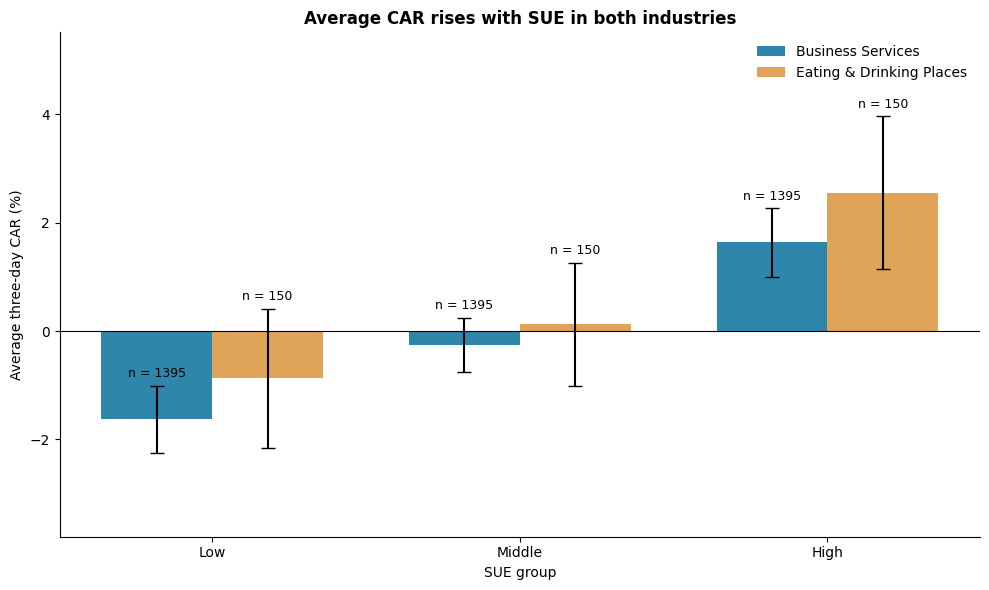

In [195]:
# Import plotting tools.
import matplotlib.pyplot as plt

# Import tools for creating the figures folder.
from pathlib import Path

# Create the output folder if it does not exist.
Path("figures").mkdir(exist_ok=True)

# Define one consistent color for each industry.
business_color = "#2E86AB"
comparison_color = "#E0A458"

# Set the positions of the three SUE groups.
x = np.arange(len(labels))

# Set the width of each bar.
width = 0.36

# Convert Business Services means to percentages.
business_mean = business_table["mean"] * 100

# Convert Business Services confidence-interval widths to percentage points.
business_ci = business_table["ci95"] * 100

# Convert comparison-industry means to percentages.
comparison_mean = comparison_table["mean"] * 100

# Convert comparison-industry confidence-interval widths.
comparison_ci = comparison_table["ci95"] * 100

# Create the figure and its plotting area.
fig, ax = plt.subplots(figsize=(10, 6))

# Plot Business Services to the left of each group position.
ax.bar(
    x - width / 2,
    business_mean,
    width,
    yerr=business_ci,
    capsize=5,
    color=business_color,
    label="Business Services"
)

# Plot Eating & Drinking Places to the right.
ax.bar(
    x + width / 2,
    comparison_mean,
    width,
    yerr=comparison_ci,
    capsize=5,
    color=comparison_color,
    label="Eating & Drinking Places"
)

# Label the number of announcements in each bar.
for i, group in enumerate(labels):

    # Position the Business Services count above its confidence interval.
    business_top = business_mean.loc[group] + business_ci.loc[group]

    # Add the Business Services count.
    ax.annotate(
        f"n = {business_table.loc[group, 'n']}",
        (x[i] - width / 2, business_top),
        xytext=(0, 6),
        textcoords="offset points",
        ha="center",
        fontsize=9
    )

    # Position the comparison count above its confidence interval.
    comparison_top = comparison_mean.loc[group] + comparison_ci.loc[group]

    # Add the comparison-industry count.
    ax.annotate(
        f"n = {comparison_table.loc[group, 'n']}",
        (x[i] + width / 2, comparison_top),
        xytext=(0, 6),
        textcoords="offset points",
        ha="center",
        fontsize=9
    )

# Mark zero abnormal return.
ax.axhline(0, color="black", linewidth=0.8)

# Label the group positions.
ax.set_xticks(x, labels)

# Add a title describing the observed result.
ax.set_title(
    "Average CAR rises with SUE in both industries",
    fontweight="bold"
)

# Label the horizontal axis.
ax.set_xlabel("SUE group")

# Label the vertical axis with its units.
ax.set_ylabel("Average three-day CAR (%)")

# Identify the industry colors.
ax.legend(frameon=False)

# Leave room for the count labels.
ax.margins(y=0.25)

# Remove the upper frame line.
ax.spines["top"].set_visible(False)

# Remove the right frame line.
ax.spines["right"].set_visible(False)

# Adjust spacing.
fig.tight_layout()

# Save Figure 1 for the slides and repository.
fig.savefig("figures/figure1_industry_comparison.png", dpi=300)

# Display the chart.
plt.show()

## Step 19 — Test High versus Low SUE Groups

Use Welch's two-sided t-test to test whether the High and Low
groups have different average CARs within each industry.

Report the High-minus-Low difference, t-statistic, and p-value.

**Source:** Week 12 in-class Welch t-test code, adapted with AI
without using a class.

In [196]:
#Import the statistical testing tools.
from scipy import stats

# Select Business Services CARs in the High group.
business_high = business_results.loc[
    business_results["sue_group"] == "High", "car"
]

# Select Business Services CARs in the Low group.
business_low = business_results.loc[
    business_results["sue_group"] == "Low", "car"
]

# Run Welch's two-sided test without assuming equal variances.
business_t, business_p = stats.ttest_ind(
    business_high,
    business_low,
    equal_var=False
)

# Calculate the High-minus-Low difference in percentage points.
business_gap = (business_high.mean() - business_low.mean()) * 100

# Select comparison-industry CARs in the High group.
comparison_high = comparison_results.loc[
    comparison_results["sue_group"] == "High", "car"
]

# Select comparison-industry CARs in the Low group.
comparison_low = comparison_results.loc[
    comparison_results["sue_group"] == "Low", "car"
]

# Run the same test for the comparison industry.
comparison_t, comparison_p = stats.ttest_ind(
    comparison_high,
    comparison_low,
    equal_var=False
)

# Calculate its High-minus-Low difference in percentage points.
comparison_gap = (
    comparison_high.mean() - comparison_low.mean()
) * 100

# Display both industries' aggregate test results.
ttest_results = pd.DataFrame({
    "Industry": ["Business Services", "Eating & Drinking Places"],
    "High minus Low (percentage points)": [
        business_gap, comparison_gap
    ],
    "t-statistic": [business_t, comparison_t],
    "p-value": [business_p, comparison_p]
})

# Show small p-values without rounding them to zero.
display(ttest_results.style.format({
    "High minus Low (percentage points)": "{:.3f}",
    "t-statistic": "{:.3f}",
    "p-value": "{:.3g}"
}))

,Industry,High minus Low (percentage points),t-statistic,p-value
0,Business Services,3.261,7.216,6.89e-13
1,Eating & Drinking Places,3.426,3.528,0.000485


## Step 20 — Regress CAR on SUE

Estimate CAR = a + b × SUE separately for each industry.
Report the slope, its p-value, R-squared, and sample size.

Use the original CAR values for the required baseline analysis.

These baseline models use ordinary OLS standard errors.
Their p-values do not account for repeated announcements
from the same company.

**Source:** Week 12 in-class regression example, adapted with AI
without using a class.

In [197]:
# Import the professor's regression tools.
import statsmodels.formula.api as smf

# Specify the Business Services regression.
business_spec = smf.ols("car ~ sue", data=business_results)

# Estimate the Business Services regression.
business_model = business_spec.fit()

# Specify the comparison-industry regression.
comparison_spec = smf.ols("car ~ sue", data=comparison_results)

# Estimate the comparison-industry regression.
comparison_model = comparison_spec.fit()

# Collect the required aggregate regression statistics.
regression_results = pd.DataFrame({
    "Industry": [
        "Business Services",
        "Eating & Drinking Places"
    ],
    "Slope (b)": [
        business_model.params["sue"],
        comparison_model.params["sue"]
    ],
    "Slope p-value": [
        business_model.pvalues["sue"],
        comparison_model.pvalues["sue"]
    ],
    "R-squared": [
        business_model.rsquared,
        comparison_model.rsquared
    ],
    "Announcements": [
        int(business_model.nobs),
        int(comparison_model.nobs)
    ]
})

# Identify the standard errors used for the baseline regressions.
print("Baseline regressions — ordinary OLS standard errors")

# Display the statistics without rounding small p-values to zero.
display(regression_results.style.format({
    "Slope (b)": "{:.4f}",
    "Slope p-value": "{:.3g}",
    "R-squared": "{:.4f}",
    "Announcements": "{:,.0f}"
}))

Baseline regressions — ordinary OLS standard errors


,Industry,Slope (b),Slope p-value,R-squared,Announcements
0,Business Services,0.1171,3.19e-05,0.0041,"4,185"
1,Eating & Drinking Places,0.0475,0.498,0.0010,450


## Step 21 — Figure 2: SUE and CAR with Regression Lines

Plot SUE against three-day CAR for both industries.
Add each industry's fitted regression line using the baseline models.

**Source:** Week 12 regression-chart example, adapted with AI
without using a class.

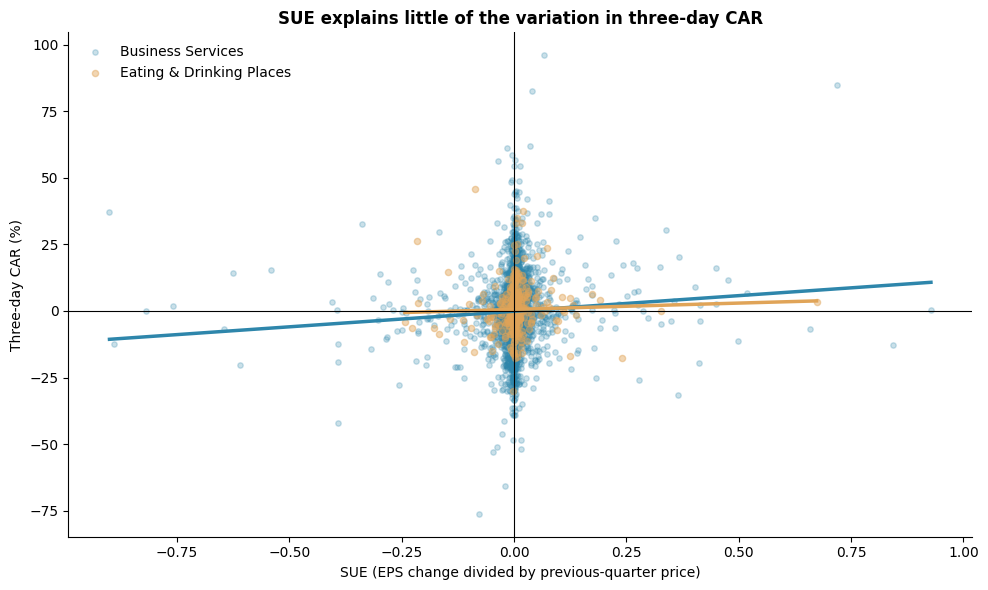

In [198]:
# Create SUE values spanning the Business Services sample.
business_grid = pd.DataFrame({
    "sue": np.linspace(
        business_results["sue"].min(),
        business_results["sue"].max(),
        100
    )
})

# Predict CAR along the Business Services regression line.
business_prediction = business_model.predict(business_grid)

# Create SUE values spanning the comparison-industry sample.
comparison_grid = pd.DataFrame({
    "sue": np.linspace(
        comparison_results["sue"].min(),
        comparison_results["sue"].max(),
        100
    )
})

# Predict CAR along the comparison-industry regression line.
comparison_prediction = comparison_model.predict(comparison_grid)

# Create one shared plotting area.
fig, ax = plt.subplots(figsize=(10, 6))

# Plot Business Services announcements.
ax.scatter(
    business_results["sue"],
    business_results["car"] * 100,
    color=business_color,
    alpha=0.25,
    s=15,
    label="Business Services"
)

# Plot comparison-industry announcements.
ax.scatter(
    comparison_results["sue"],
    comparison_results["car"] * 100,
    color=comparison_color,
    alpha=0.45,
    s=20,
    label="Eating & Drinking Places"
)

# Draw the Business Services regression line.
ax.plot(
    business_grid["sue"],
    business_prediction * 100,
    color=business_color,
    linewidth=2.5
)

# Draw the comparison-industry regression line.
ax.plot(
    comparison_grid["sue"],
    comparison_prediction * 100,
    color=comparison_color,
    linewidth=2.5
)

# Mark zero abnormal return.
ax.axhline(0, color="black", linewidth=0.8)

# Mark zero earnings surprise.
ax.axvline(0, color="black", linewidth=0.8)

# State a finding supported by both small R-squared values.
ax.set_title(
    "SUE explains little of the variation in three-day CAR",
    fontweight="bold"
)

# Label SUE in its original decimal units.
ax.set_xlabel("SUE (EPS change divided by previous-quarter price)")

# Label CAR in percentage units.
ax.set_ylabel("Three-day CAR (%)")

# Identify each industry's consistent color.
ax.legend(frameon=False)

# Remove the top border.
ax.spines["top"].set_visible(False)

# Remove the right border.
ax.spines["right"].set_visible(False)

# Adjust spacing.
fig.tight_layout()

# Save the figure.
fig.savefig("figures/figure2_sue_car_regression.png", dpi=300)

# Display the figure.
plt.show()

## Step 22 — Investigate Loss-Making Announcements

Check whether the industries differ in the share of announcements
with negative quarterly EPS, separately within each SUE group.

This checks one possible explanation for the differences in average CAR.
It does not establish that losses cause those differences.

**Source:** Week 12 loss-indicator example and Project 3 guidance,
adapted with AI.

,Business Services (%),Eating & Drinking Places (%)
sue_group,,
Low,53.26,30.00
Middle,20.65,7.33
High,24.66,17.33


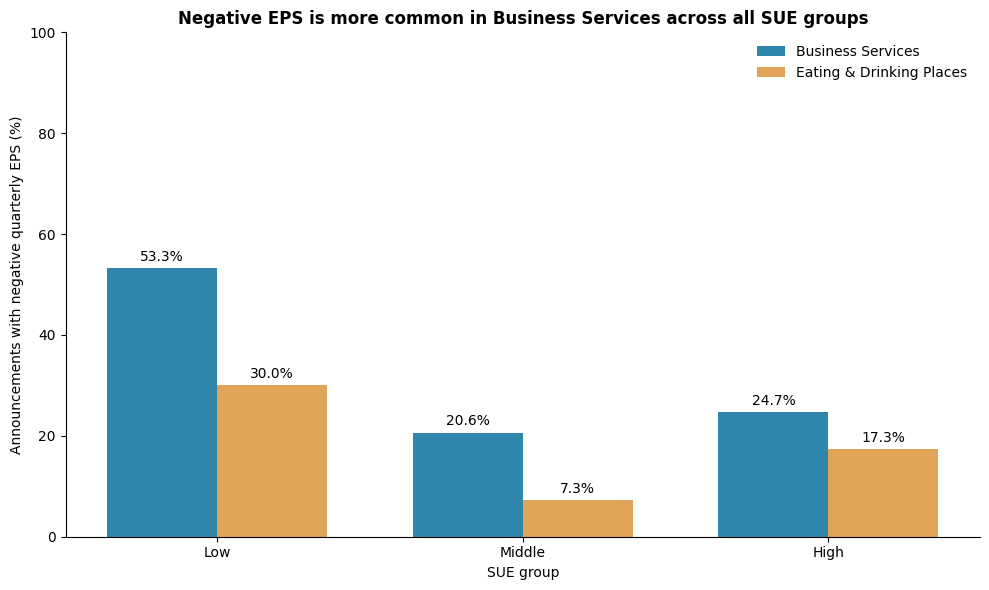

In [199]:
# Mark Business Services announcements with negative quarterly EPS.
business_results["loss"] = (
    business_results["epspxq"] < 0
).astype(int)

# Mark comparison-industry announcements with negative quarterly EPS.
comparison_results["loss"] = (
    comparison_results["epspxq"] < 0
).astype(int)

# Calculate the negative-EPS share in each Business Services SUE group.
business_loss_share = business_results.groupby(
    "sue_group", observed=True
)["loss"].mean()

# Calculate the negative-EPS share in each comparison SUE group.
comparison_loss_share = comparison_results.groupby(
    "sue_group", observed=True
)["loss"].mean()

# Convert the Business Services shares to percentages.
business_loss_percent = business_loss_share * 100

# Convert the comparison-industry shares to percentages.
comparison_loss_percent = comparison_loss_share * 100

# Combine the aggregate percentages for inspection.
loss_table = pd.DataFrame({
    "Business Services (%)": business_loss_percent,
    "Eating & Drinking Places (%)": comparison_loss_percent
})

# Display the percentages.
display(loss_table.round(2))

# Create the figure.
fig, ax = plt.subplots(figsize=(10, 6))

# Plot Business Services shares.
ax.bar(
    x - width / 2,
    business_loss_percent,
    width,
    color=business_color,
    label="Business Services"
)

# Plot comparison-industry shares.
ax.bar(
    x + width / 2,
    comparison_loss_percent,
    width,
    color=comparison_color,
    label="Eating & Drinking Places"
)

# Add percentage labels to each set of bars.
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.1f%%", padding=3)

# Label the SUE groups.
ax.set_xticks(x, labels)

# State the finding shown by the data.
ax.set_title(
    "Negative EPS is more common in Business Services across all SUE groups",
    fontweight="bold"
)

# Label the horizontal axis.
ax.set_xlabel("SUE group")

# Label the vertical axis and units.
ax.set_ylabel("Announcements with negative quarterly EPS (%)")

# Use a shared percentage scale.
ax.set_ylim(0, 100)

# Identify the consistent industry colors.
ax.legend(frameon=False)

# Remove the top border.
ax.spines["top"].set_visible(False)

# Remove the right border.
ax.spines["right"].set_visible(False)

# Adjust spacing.
fig.tight_layout()

# Save Figure 3.
fig.savefig("figures/figure3_negative_eps_share.png", dpi=300)

# Display the figure.
plt.show()

## Step 23 — Check Fiscal-Year Effects and Loss Status

Estimate three models for each industry:
1. CAR explained by SUE.
2. Add fiscal-year effects.
3. Add loss status and its interaction with SUE.

Use company-clustered standard errors and the original CAR values.

These models use company-clustered standard errors to account
for dependence among announcements from the same company.

The Base model has the same specification as Step 20, but its
standard errors and p-values can differ because of clustering.

**Source:** Week 12 regression-model comparison, adapted with AI
without using a class.

In [200]:
# Import the side-by-side regression display.
from statsmodels.iolib.summary2 import summary_col

# Copy the inputs needed for all three models.
business_reg = business_results[
    ["car", "sue", "fyearq", "epspxq", "gvkey"]
].copy()

# Remove rows with missing model inputs.
business_reg = business_reg.dropna()

# Convert fiscal year to an integer.
business_reg["fyearq"] = business_reg["fyearq"].astype(int)

# Mark negative-EPS announcements as 1 and others as 0.
business_reg["loss"] = (business_reg["epspxq"] < 0).astype(int)

# Model 1: estimate the baseline relationship.
business_m1 = smf.ols(
    "car ~ sue", data=business_reg
).fit(
    cov_type="cluster",
    cov_kwds={"groups": business_reg["gvkey"]}
)

# Model 2: add fiscal-year effects.
business_m2 = smf.ols(
    "car ~ sue + C(fyearq)", data=business_reg
).fit(
    cov_type="cluster",
    cov_kwds={"groups": business_reg["gvkey"]}
)

# Model 3: allow the SUE slope to differ by loss status.
business_m3 = smf.ols(
    "car ~ sue * loss + C(fyearq)", data=business_reg
).fit(
    cov_type="cluster",
    cov_kwds={"groups": business_reg["gvkey"]}
)

# Display all three models.
print("Business Services — company-clustered standard errors")
display(summary_col(
    [business_m1, business_m2, business_m3],
    stars=True,
    model_names=["Base", "Year effects", "Year + loss"],
    regressor_order=["sue", "loss", "sue:loss"],
    drop_omitted=True
))

Business Services — company-clustered standard errors


,Base,Year effects,Year + loss
sue,0.1171**,0.1201**,0.2970**
,(0.0583),(0.0586),(0.1234)
loss,,,-0.0155***
,,,(0.0042)
sue:loss,,,-0.2962**
,,,(0.1338)
R-squared,0.0041,0.0057,0.0157
R-squared Adj.,0.0039,0.0043,0.0138


In [201]:
# Source: Week 12 model comparison, adapted with AI without a class.

# Import the side-by-side regression display.
from statsmodels.iolib.summary2 import summary_col

# Copy the inputs needed for all three models.
comparison_reg = comparison_results[
    ["car", "sue", "fyearq", "epspxq", "gvkey"]
].copy()

# Remove rows with missing model inputs.
comparison_reg = comparison_reg.dropna()

# Convert fiscal year to an integer.
comparison_reg["fyearq"] = comparison_reg["fyearq"].astype(int)

# Mark negative-EPS announcements as 1 and others as 0.
comparison_reg["loss"] = (
    comparison_reg["epspxq"] < 0
).astype(int)

# Model 1: estimate the baseline relationship.
comparison_m1 = smf.ols(
    "car ~ sue",
    data=comparison_reg
).fit(
    cov_type="cluster",
    cov_kwds={"groups": comparison_reg["gvkey"]}
)

# Model 2: add fiscal-year effects.
comparison_m2 = smf.ols(
    "car ~ sue + C(fyearq)",
    data=comparison_reg
).fit(
    cov_type="cluster",
    cov_kwds={"groups": comparison_reg["gvkey"]}
)

# Model 3: allow the SUE slope to differ by loss status.
comparison_m3 = smf.ols(
    "car ~ sue * loss + C(fyearq)",
    data=comparison_reg
).fit(
    cov_type="cluster",
    cov_kwds={"groups": comparison_reg["gvkey"]}
)

# Identify the industry and standard-error method.
print("Eating & Drinking Places — company-clustered standard errors")

# Display all three models side by side.
display(summary_col(
    [comparison_m1, comparison_m2, comparison_m3],
    stars=True,
    model_names=["Base", "Year effects", "Year + loss"],
    regressor_order=["sue", "loss", "sue:loss"],
    drop_omitted=True
))

Eating & Drinking Places — company-clustered standard errors


,Base,Year effects,Year + loss
sue,0.0475,0.0515,0.1779
,(0.0855),(0.0851),(0.1859)
loss,,,0.0088
,,,(0.0146)
sue:loss,,,-0.1657
,,,(0.1911)
R-squared,0.0010,0.0079,0.0120
R-squared Adj.,-0.0012,-0.0055,-0.0059


## Step 24 — Directly Test Whether Industry Slopes Differ

Combine both industries and interact SUE with an industry indicator.
Test whether the SUE slope differs between Eating & Drinking Places
and Business Services.

Use original CAR and company-clustered standard errors.

**Source:** AI-assisted extension of the Week 12 interaction regression.

In [202]:
# Copy the Business Services model inputs.
business_test = business_results[["gvkey", "sue", "car"]].copy()

# Set Business Services as the reference industry.
business_test["comparison_industry"] = 0

# Copy the Eating & Drinking Places model inputs.
comparison_test = comparison_results[["gvkey", "sue", "car"]].copy()

# Identify Eating & Drinking Places with a value of 1.
comparison_test["comparison_industry"] = 1

# Combine the two samples.
industry_test = pd.concat(
    [business_test, comparison_test],
    ignore_index=True
)

# Remove missing model inputs before defining company clusters.
industry_test = industry_test.dropna()

# Specify separate intercepts and SUE slopes for the industries.
industry_spec = smf.ols(
    "car ~ sue * comparison_industry",
    data=industry_test
)

# Estimate the model with standard errors clustered by company.
industry_model = industry_spec.fit(
    cov_type="cluster",
    cov_kwds={"groups": industry_test["gvkey"]}
)

# Extract the Business Services slope.
business_slope = industry_model.params["sue"]

# Extract the comparison-minus-Business Services slope difference.
slope_difference = industry_model.params[
    "sue:comparison_industry"
]

# Calculate the Eating & Drinking Places slope.
comparison_slope = business_slope + slope_difference

# Extract the p-value for the slope difference.
difference_p = industry_model.pvalues[
    "sue:comparison_industry"
]

# Extract the 95% confidence interval for the slope difference.
difference_ci = industry_model.conf_int().loc[
    "sue:comparison_industry"
]

# Identify the standard errors used for the industry comparison.
print("Industry slope comparison — company-clustered standard errors")

# Display the two estimated slopes.
print(f"Business Services slope: {business_slope:.4f}")
print(f"Eating & Drinking Places slope: {comparison_slope:.4f}")

# Display the direct comparison.
print(f"Comparison minus Business Services: {slope_difference:.4f}")
print(f"Slope-difference p-value: {difference_p:.4g}")

# Display the confidence interval.
print(
    "95% confidence interval for the slope difference:",
    f"[{difference_ci.iloc[0]:.4f}, {difference_ci.iloc[1]:.4f}]"
)

Industry slope comparison — company-clustered standard errors
Business Services slope: 0.1171
Eating & Drinking Places slope: 0.0475
Comparison minus Business Services: -0.0696
Slope-difference p-value: 0.497
95% confidence interval for the slope difference: [-0.2704, 0.1312]
